In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from transformers import pipeline
from transformers import BertTokenizer

C:\Users\jorda\Code\ml-notebooks\courses\natural-language-processing\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import kagglehub
from pathlib import Path

# Mental Health Corpus (27,977 posts), downloaded once to the kagglehub cache
MH_DIR = Path(kagglehub.dataset_download("reihanenamdari/mental-health-corpus"))
df = pd.read_csv(MH_DIR / "mental_health.csv")

In [3]:
print(df.head())

                                                text  label
0  dear american teens question dutch person hear...      0
1  nothing look forward lifei dont many reasons k...      1
2  music recommendations im looking expand playli...      0
3  im done trying feel betterthe reason im still ...      1
4  worried  year old girl subject domestic physic...      1


In [4]:
print(df.size)
print(df.shape)

55954
(27977, 2)


In [5]:
print(pd.DataFrame(np.unique(df['label'], return_counts=True), index=['value', 'count']))

           0      1
value      0      1
count  14139  13838


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 27977 entries, 0 to 27976
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    27977 non-null  str  
 1   label   27977 non-null  int64
dtypes: int64(1), str(1)
memory usage: 437.3 KB


In [7]:
print(df.isnull().sum())

text     0
label    0
dtype: int64


C:\Users\jorda\AppData\Local\Temp\ipykernel_29008\2929316169.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='label', palette='rocket_r')


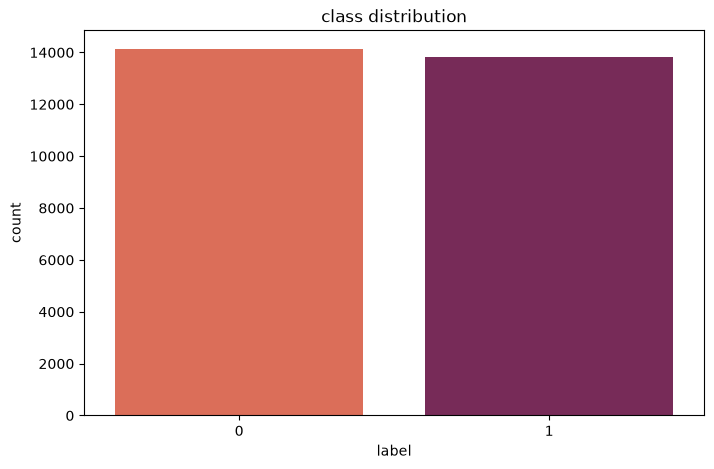

In [8]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='label', palette='rocket_r')
plt.xlabel('label')
plt.ylabel('count')
plt.title('class distribution')
plt.show()

In [9]:
x = df.text
y = df.label

In [10]:
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

custom_stopwords = [
    'i', 'me', 'my', 'myself', 'we', 'our', 'ours', 'ourselves', 'you', "you're", "you've", "you'll", "you'd",
    'your', 'yours', 'yourself', 'yourselves', 'he', 'him', 'his', 'himself', 'she', "she's", 'her', 'hers', 'herself',
    'it', "it's", 'its', 'itself', 'they', 'them', 'their', 'theirs', 'themselves', 'what', 'which', 'who', 'whom', 'this',
    'that', "that'll", 'these', 'those', 'am', 'is', 'are', 'was', 'were', 'be', 'been', 'being', 'have', 'has', 'had',
    'having', 'do', 'does', 'did', 'doing', 'a', 'an', 'the', 'and', 'but', 'if', 'or', 'because', 'as', 'until', 'while',
    'of', 'at', 'by', 'for', 'with', 'about', 'against', 'between', 'into', 'through', 'during', 'before', 'after', 'above',
    'below', 'to', 'from', 'up', 'down', 'in', 'out', 'on', 'off', 'over', 'under', 'again', 'further', 'then', 'once',
    'here', 'there', 'when', 'where', 'why', 'how', 'all', 'any', 'both', 'each', 'few', 'more', 'most', 'other', 'some',
    'such', 'no', 'nor', 'not', 'only', 'own', 'same', 'so', 'than', 'too', 'very', 's', 't', 'can', 'will', 'just', 'don',
    "don't", 'should', "should've", 'now', 'd', 'll', 'm', 'o', 're', 've', 'y', 'ain', 'aren', "aren't", 'couldn', "couldn't",
    'didn', "didn't", 'doesn', "doesn't", 'hadn', "hadn't", 'hasn', "hasn't", 'haven', "haven't", 'isn', "isn't", 'ma', 'mightn',
    "mightn't", 'mustn', "mustn't", 'needn', "needn't", 'shan', "shan't", 'shouldn', "shouldn't", 'wasn', "wasn't", 'weren',
    "weren't", 'won', "won't", 'wouldn', "wouldn't", "im", "ive", "ill", "id", "its", "itll", "itd", "hes", "hell", "hed", "shes",
    "shell", "shed", "were", "weve", "well", "wed", "theyre", "theyve", "theyll", "theyd", "youre", "youll", "youve", "youd",
    'dont', 'cant', 'couldnt', 'didnt', 'doesnt', 'hadnt', 'hasnt', 'havent', 'isnt', 'mightnt', 'mustnt', 'neednt', 'shant'
]

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^\w\s]+', '', text)
    text = ' '.join([word for word in text.split() if word not in custom_stopwords])
    return text

df['text'] = df['text'].astype(str).apply(clean_text)

In [11]:
print(df.head())

                                                text  label
0  dear american teens question dutch person hear...      0
1  nothing look forward lifei many reasons keep g...      1
2  music recommendations looking expand playlist ...      0
3  done trying feel betterthe reason still alive ...      1
4  worried year old girl subject domestic physica...      1


In [12]:
x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.2, random_state=42)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.4, random_state=42)

In [13]:
print(x_train.shape, x_val.shape, x_test.shape)

(22381,) (3357,) (2239,)


In [14]:
analyzer = 'word'
ngram_range = (1, 5)
min_df = 3
max_df = 0.8
max_features = 5000
stop_words = 'english'
sublinear_tf = True

In [15]:
lr = Pipeline([('tfidf', TfidfVectorizer(
        analyzer=analyzer,
        ngram_range=ngram_range,
        min_df=min_df,
        max_df=max_df,
        max_features=max_features,
        sublinear_tf=sublinear_tf
    )),
    ('lrc', LogisticRegression(max_iter=1000, random_state=42))
])

In [16]:
lr.fit(x_train, y_train)

C:\Users\jorda\Code\ml-notebooks\courses\natural-language-processing\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_df=0.8, max_features=5000, min_df=3,
                                 ngram_range=(1, 5), sublinear_tf=True)),
                ('lrc', LogisticRegression(max_iter=1000, random_state=42))])

In [17]:
y_val_pred = lr.predict(x_val)
validation_accuracy = accuracy_score(y_val, y_val_pred)
print("Validation Accuracy:", validation_accuracy)

Validation Accuracy: 0.92463509085493


In [18]:
y_test_pred = lr.predict(x_test)
test_accuracy = accuracy_score(y_test, y_test_pred)
print("Test Accuracy:", test_accuracy)

Test Accuracy: 0.9245198749441715


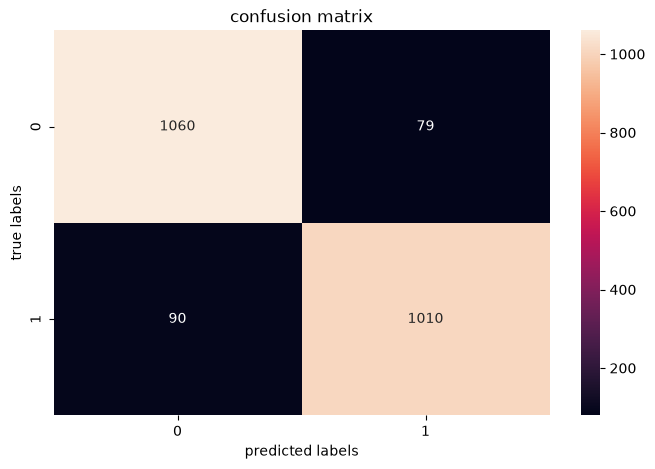

In [19]:
c_matrix = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(8, 5))
class_names = df['label'].unique()
sns.heatmap(c_matrix, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names)
plt.xlabel("predicted labels")
plt.ylabel("true labels")
plt.title("confusion matrix")
plt.show()

In [20]:
report = classification_report(y_test, y_test_pred)
print(report)

              precision    recall  f1-score   support

           0       0.92      0.93      0.93      1139
           1       0.93      0.92      0.92      1100

    accuracy                           0.92      2239
   macro avg       0.92      0.92      0.92      2239
weighted avg       0.92      0.92      0.92      2239



In [21]:
from pathlib import Path

MODEL_DIR = Path.home() / ".cache" / "ml-notebooks" / "natural-language-processing/logistic-regression-tfidf"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
import joblib

joblib.dump(lr, MODEL_DIR / 'model.joblib')

['C:\\Users\\jorda\\.cache\\ml-notebooks\\natural-language-processing\\logistic-regression-tfidf\\model.joblib']

In [22]:
# Load the model
lr = joblib.load(MODEL_DIR / 'model.joblib')

# Wrap the input string in a list before passing it to the predict method
ans = lr.predict_proba(["i feel like killing my self"])

# Print the prediction
print(ans)

[[0.1268554 0.8731446]]
